In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pyPPG import PPG, Fiducials, Biomarkers
from pyPPG.datahandling import load_data, plot_fiducials, save_data
import pyPPG.preproc as PP
import pyPPG.fiducials as FP
import pyPPG.biomarkers as BM
import pyPPG.ppg_sqi as SQI

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
file_path = "Sample_PPG_CSV_125Hz.csv"

fs = 125  # CHANGE THIS to your actual sampling frequency

raw_data = pd.read_csv(file_path)

ppg_raw = raw_data.iloc[:, 0].values

print("Number of samples:", len(ppg_raw))
print("Sampling frequency:", fs, "Hz")
print("Duration:", len(ppg_raw) / fs, "seconds")

Number of samples: 15000
Sampling frequency: 125 Hz
Duration: 120.0 seconds


In [3]:
from dotmap import DotMap

signal = DotMap()

signal.v = np.asarray(ppg_raw, dtype=float)
signal.fs = fs

signal.start_sig = 0
signal.end_sig = len(signal.v) - 1
signal.name = "My_PPG"

print("Signal prepared.")
print("Samples:", len(signal.v))
print("Fs:", signal.fs)

Signal prepared.
Samples: 15000
Fs: 125


In [4]:
import matplotlib
print(matplotlib.__version__)

3.10.9


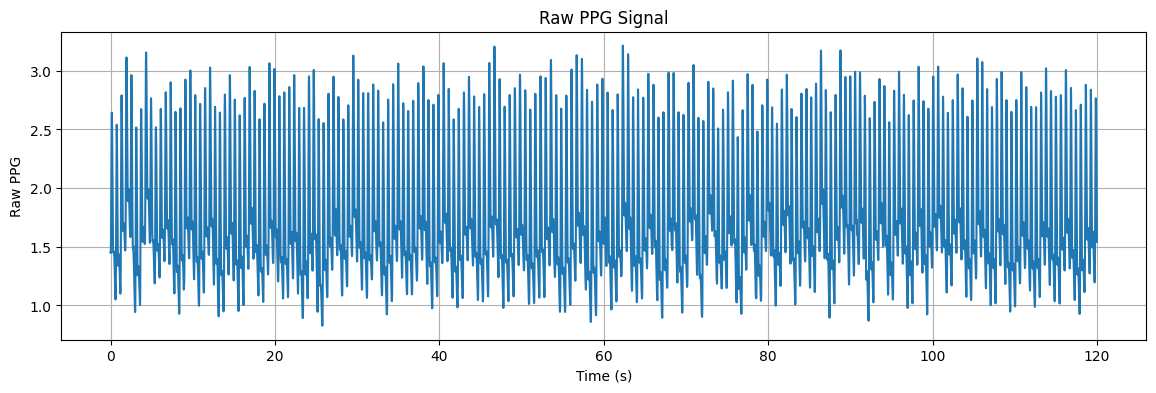

In [5]:
time = np.arange(len(signal.v)) / signal.fs

plt.figure(figsize=(14, 4))

plt.plot(time, signal.v)

plt.xlabel("Time (s)")
plt.ylabel("Raw PPG")
plt.title("Raw PPG Signal")

plt.grid(True)
plt.show()

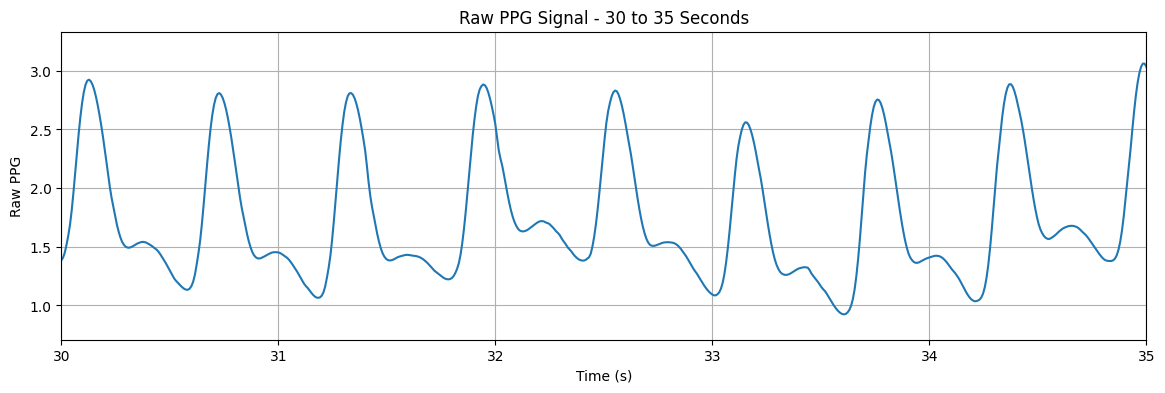

In [7]:
plt.figure(figsize=(14, 4))

plt.plot(time, signal.v)

plt.xlim(30, 35)

plt.xlabel("Time (s)")
plt.ylabel("Raw PPG")
plt.title("Raw PPG Signal - 30 to 35 Seconds")

plt.grid(True)
plt.show()

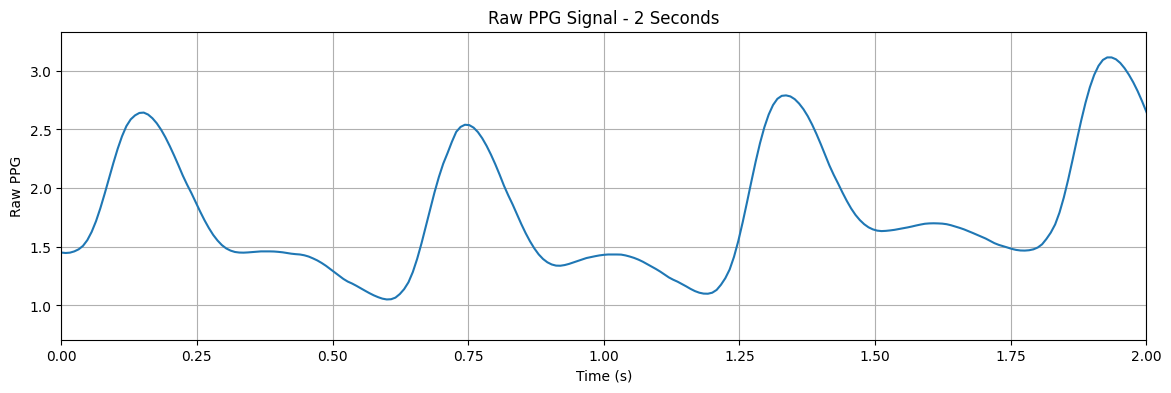

In [6]:
plt.figure(figsize=(14, 4))

plt.plot(time, signal.v)

plt.xlim(0, 2)

plt.xlabel("Time (s)")
plt.ylabel("Raw PPG")
plt.title("Raw PPG Signal - 2 Seconds")

plt.grid(True)
plt.show()

In [8]:
signal.filtering = True

signal.fL = 0.5
signal.fH = 12
signal.order = 4

signal.sm_wins = {
    'ppg': 50,
    'vpg': 10,
    'apg': 10,
    'jpg': 10
}

prep = PP.Preprocess(
    fL=signal.fL,
    fH=signal.fH,
    order=signal.order,
    sm_wins=signal.sm_wins
)

In [9]:
signal.ppg, signal.vpg, signal.apg, signal.jpg = prep.get_signals(
    s=signal
)

print("Preprocessing complete!")

Preprocessing complete!


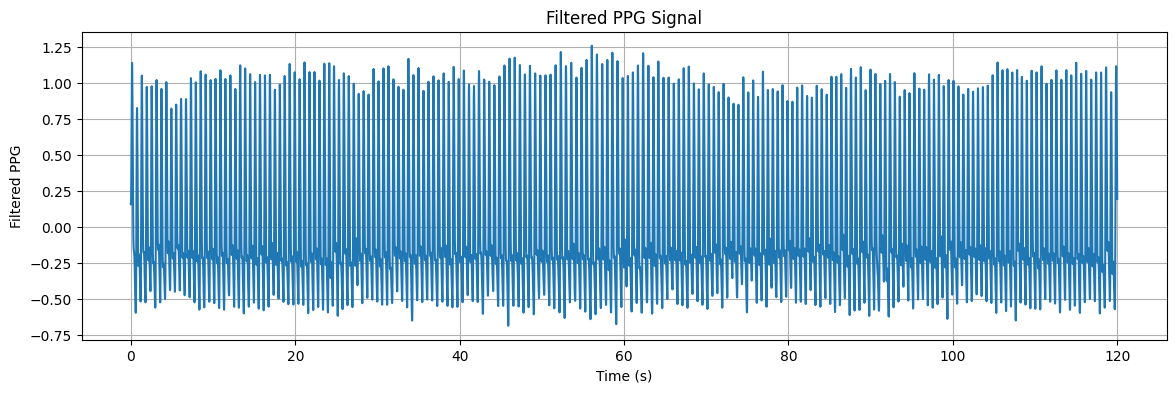

In [10]:
time = np.arange(len(signal.ppg)) / signal.fs

plt.figure(figsize=(14, 4))

plt.plot(time, signal.ppg)

plt.xlabel("Time (s)")
plt.ylabel("Filtered PPG")
plt.title("Filtered PPG Signal")

plt.grid(True)
plt.show()

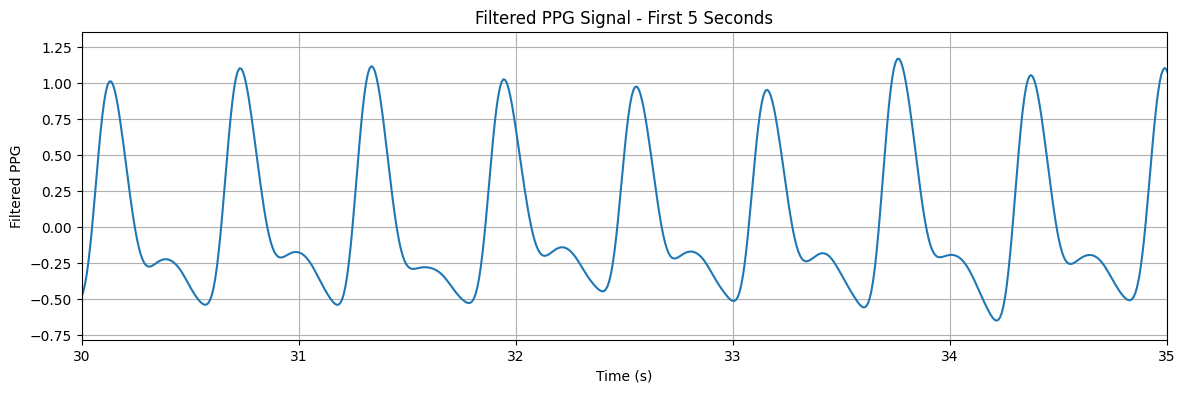

In [11]:
plt.figure(figsize=(14, 4))

plt.plot(time, signal.ppg)

plt.xlim(30, 35)

plt.xlabel("Time (s)")
plt.ylabel("Filtered PPG")
plt.title("Filtered PPG Signal - First 5 Seconds")

plt.grid(True)
plt.show()

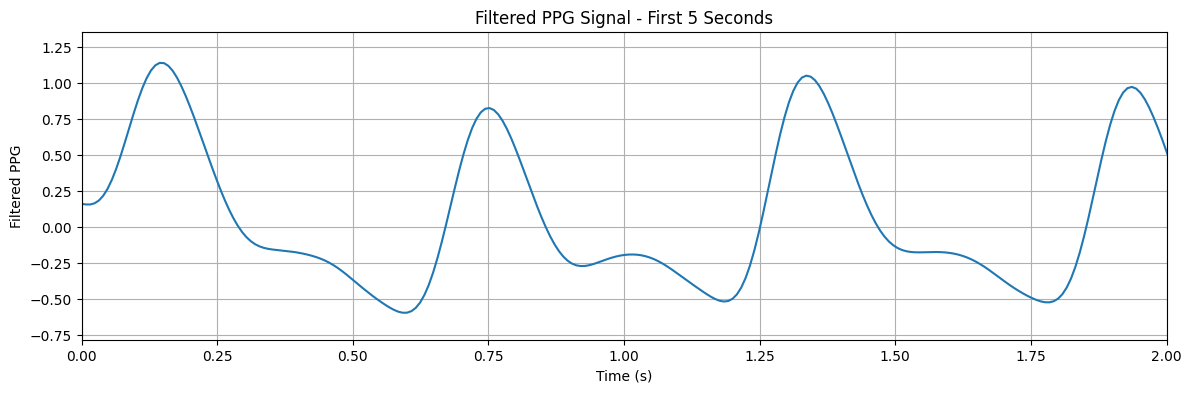

In [12]:
plt.figure(figsize=(14, 4))

plt.plot(time, signal.ppg)

plt.xlim(0, 2)

plt.xlabel("Time (s)")
plt.ylabel("Filtered PPG")
plt.title("Filtered PPG Signal - First 5 Seconds")

plt.grid(True)
plt.show()

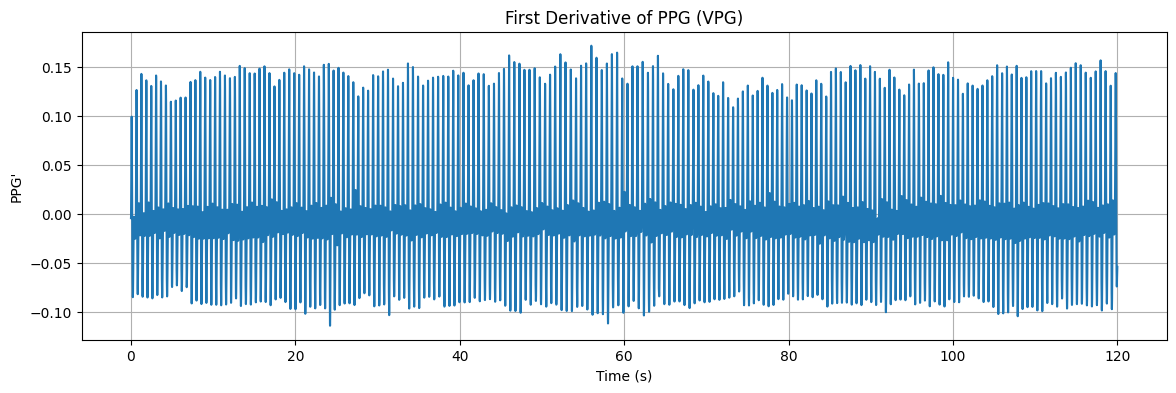

In [13]:
plt.figure(figsize=(14, 4))

plt.plot(time, signal.vpg)

plt.xlabel("Time (s)")
plt.ylabel("PPG'")
plt.title("First Derivative of PPG (VPG)")

plt.grid(True)
plt.show()

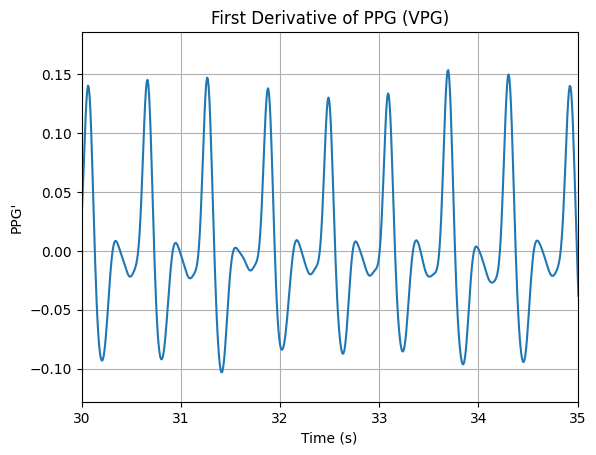

In [14]:
plt.plot(time, signal.vpg)

plt.xlim(30, 35)

plt.xlabel("Time (s)")
plt.ylabel("PPG'")
plt.title("First Derivative of PPG (VPG)")

plt.grid(True)
plt.show()

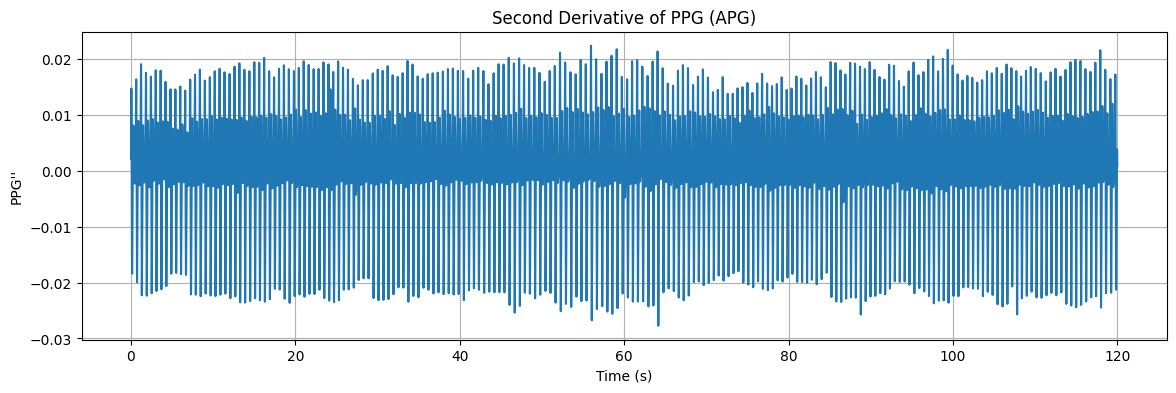

In [15]:
plt.figure(figsize=(14, 4))

plt.plot(time, signal.apg)

plt.xlabel("Time (s)")
plt.ylabel("PPG''")
plt.title("Second Derivative of PPG (APG)")

plt.grid(True)
plt.show()

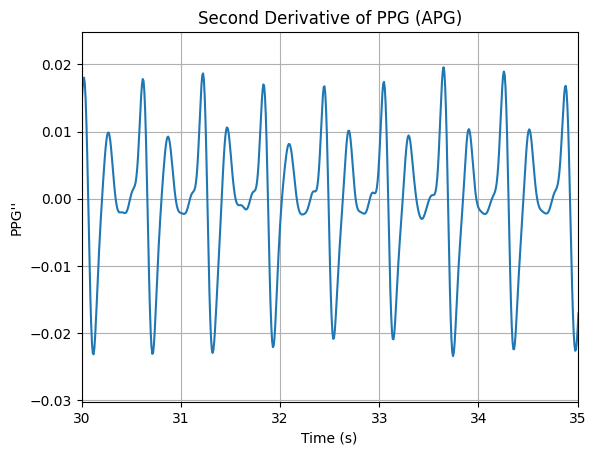

In [16]:
plt.plot(time, signal.apg)

plt.xlim(30, 35)

plt.xlabel("Time (s)")
plt.ylabel("PPG''")
plt.title("Second Derivative of PPG (APG)")

plt.grid(True)
plt.show()

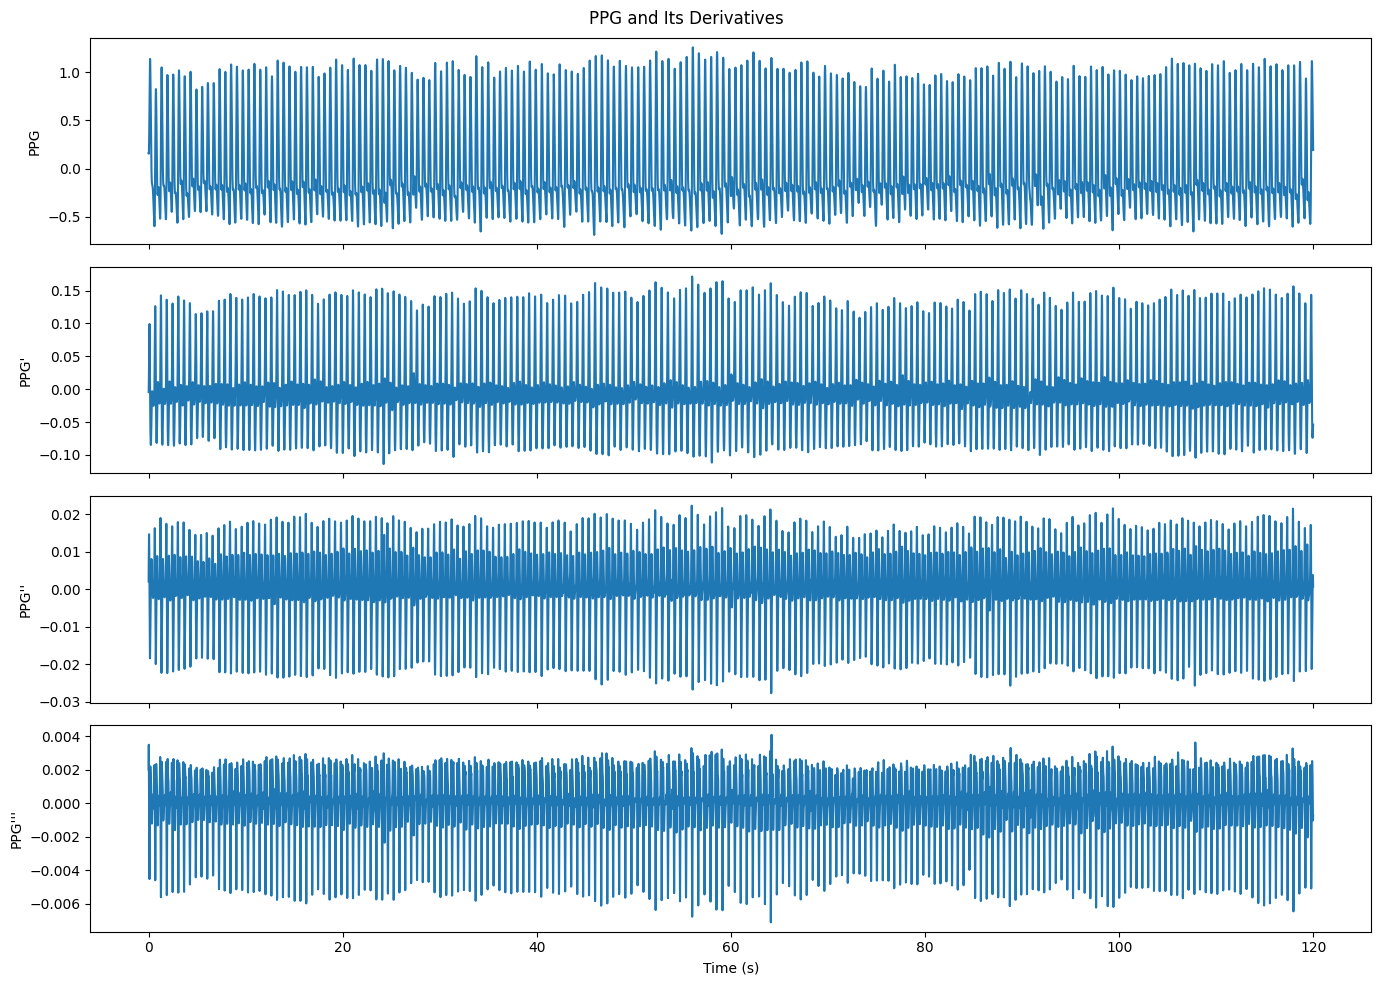

In [20]:
fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)

axes[0].plot(time, signal.ppg)
axes[0].set_ylabel("PPG")

axes[1].plot(time, signal.vpg)
axes[1].set_ylabel("PPG'")

axes[2].plot(time, signal.apg)
axes[2].set_ylabel("PPG''")

axes[3].plot(time, signal.jpg)
axes[3].set_ylabel("PPG'''")
axes[3].set_xlabel("Time (s)")

fig.suptitle("PPG and Its Derivatives")

plt.tight_layout()
plt.show()

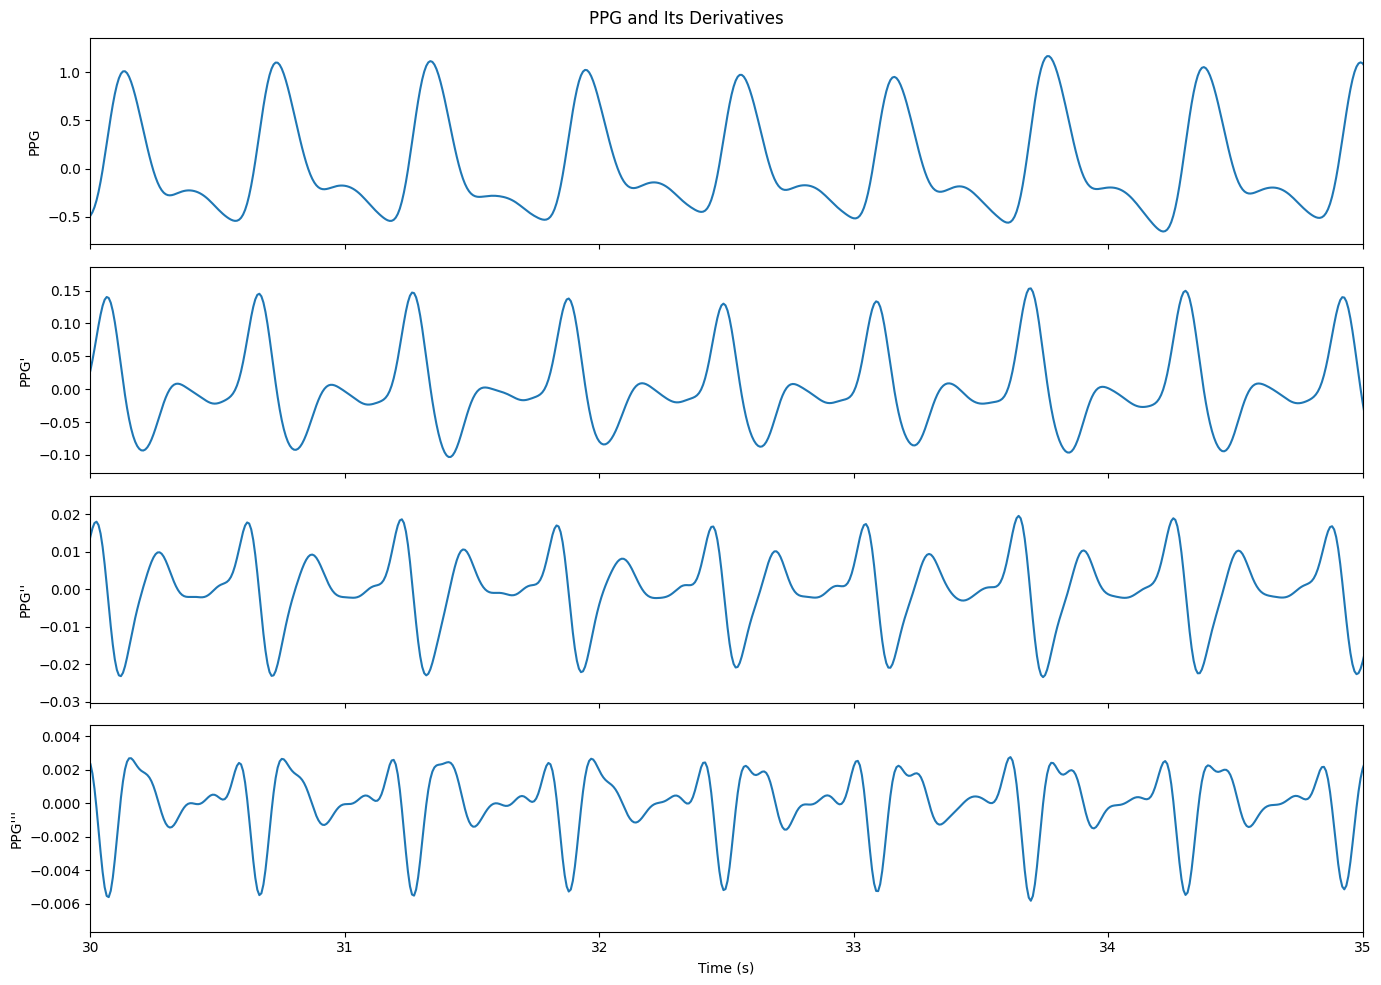

In [21]:
fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)

axes[0].plot(time, signal.ppg)
axes[0].set_ylabel("PPG")

axes[1].plot(time, signal.vpg)
axes[1].set_ylabel("PPG'")

axes[2].plot(time, signal.apg)
axes[2].set_ylabel("PPG''")

axes[3].plot(time, signal.jpg)
axes[3].set_ylabel("PPG'''")
axes[3].set_xlabel("Time (s)")

fig.suptitle("PPG and Its Derivatives")

# Show only the first 5 seconds
axes[0].set_xlim(30, 35)

plt.tight_layout()
plt.show()

In [22]:
correction = pd.DataFrame()

corr_on = ['on', 'dn', 'dp', 'v', 'w', 'f']

correction.loc[0, corr_on] = True

signal.correction = correction

In [23]:
s = PPG(
    signal,
    check_ppg_len=True
)

print("PPG object created.")

PPG object created.


In [24]:
fpex = FP.FpCollection(s=s)

fiducials = fpex.get_fiducials(s=s)

print(fiducials.head())

                 on   sp   dn   dp  off    u    v    w    a    b    c    d  \
Index of pulse                                                               
0                74   94  115  127  148   85  102  119   78   91   97   97   
1               148  167  193  197  222  158  175  194  152  164  168  168   
2               222  242  264  276  297  234  250  268  227  239  244  244   
3               297  317  340  345  371  308  325  341  302  314  319  319   
4               371  391  414  422  446  382  399  417  376  388  392  392   

                  e    f   p1   p2  
Index of pulse                      
0               110  129   97  115  
1               183  203  168  188  
2               259  278  244  264  
3               333  344  319  338  
4               407  423  392  413  


In [25]:
print(fiducials.columns)

Index(['on', 'sp', 'dn', 'dp', 'off', 'u', 'v', 'w', 'a', 'b', 'c', 'd', 'e',
       'f', 'p1', 'p2'],
      dtype='object')


In [26]:
systolic_peaks = fiducials["sp"].dropna().astype(int).values

print("Number of systolic peaks:", len(systolic_peaks))

print("First 10 peak locations:")
print(systolic_peaks[:10])

Number of systolic peaks: 187
First 10 peak locations:
[ 94 167 242 317 391 465 540 615 689 763]


In [27]:
peak_times = systolic_peaks / signal.fs

print(peak_times[:10])

[0.752 1.336 1.936 2.536 3.128 3.72  4.32  4.92  5.512 6.104]


In [28]:
onsets = fiducials["on"].dropna().astype(int).values

print("Number of onsets:", len(onsets))
print(onsets[:10])

Number of onsets: 187
[ 74 148 222 297 371 446 519 596 669 743]


In [29]:
fp = Fiducials(fp=fiducials)

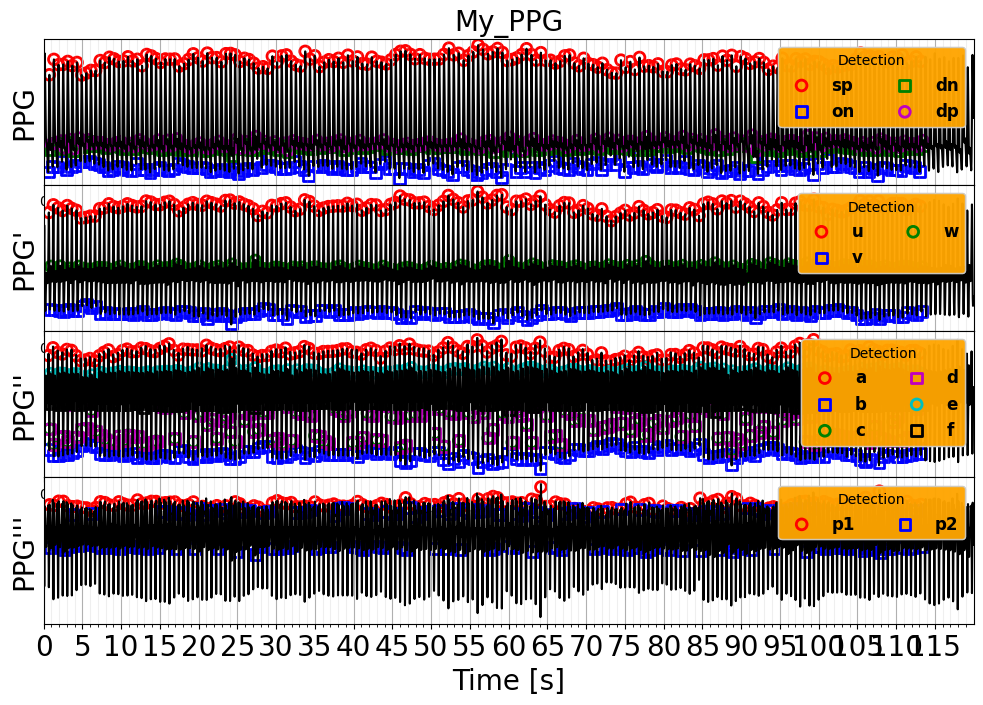

Figure has been saved in the "temp_dir\PPG_Figures\".


In [30]:
plot_fiducials(
    s,
    fp,
    savingfolder="temp_dir",
    legend_fontsize=12
)

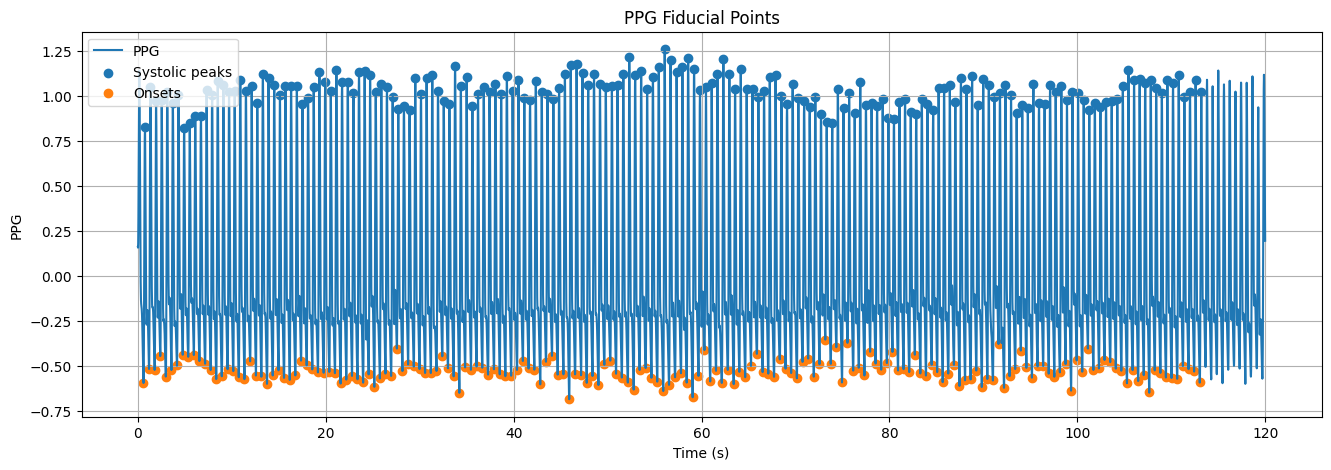

In [33]:
plt.figure(figsize=(16, 5))

plt.plot(time, signal.ppg, label="PPG")

plt.scatter(
    systolic_peaks / signal.fs,
    signal.ppg[systolic_peaks],
    label="Systolic peaks"
)

plt.scatter(
    onsets / signal.fs,
    signal.ppg[onsets],
    label="Onsets"
)

plt.xlabel("Time (s)")
plt.ylabel("PPG")
plt.title("PPG Fiducial Points")

plt.legend()
plt.grid(True)

plt.show()

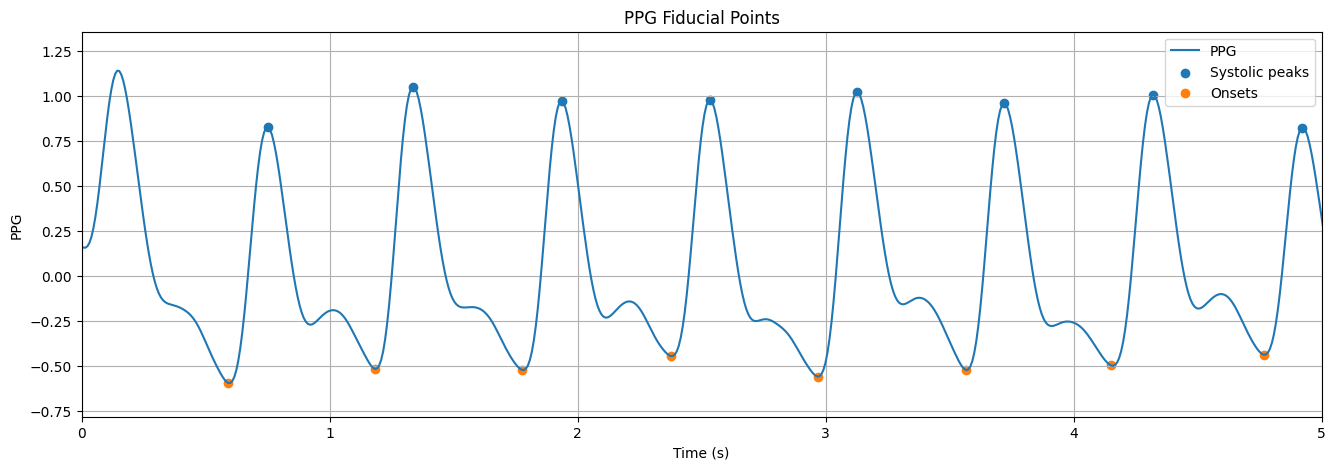

In [34]:
plt.figure(figsize=(16, 5))

plt.plot(time, signal.ppg, label="PPG")

plt.scatter(
    systolic_peaks / signal.fs,
    signal.ppg[systolic_peaks],
    label="Systolic peaks"
)

plt.scatter(
    onsets / signal.fs,
    signal.ppg[onsets],
    label="Onsets"
)

plt.xlabel("Time (s)")
plt.ylabel("PPG")
plt.title("PPG Fiducial Points")

plt.xlim(0, 5)

plt.legend()
plt.grid(True)

plt.show()

In [35]:
bmex = BM.BmCollection(
    s=s,
    fp=fp
)

bm_defs, bm_vals, bm_stats = bmex.get_biomarkers()

no more peaks
no more peaks
no more peaks
no more peaks


In [36]:
print("Biomarker categories:")
print(bm_vals.keys())

Biomarker categories:
dict_keys(['ppg_sig', 'sig_ratios', 'ppg_derivs', 'derivs_ratios'])


In [37]:
for category in bm_vals:
    print("\n", category)
    print(bm_vals[category])


 ppg_sig
name            TimeStamp    Tpi    Tpp   Tsys   Tdia    Tsp    Tdp  deltaT  \
Index of pulse                                                                
0                      74  0.592  0.584  0.328  0.168  0.160  0.424   0.264   
1                     148  0.592  0.600  0.360  0.200  0.152  0.392   0.240   
2                     222  0.600  0.600  0.336  0.168  0.160  0.432   0.272   
3                     297  0.592  0.592  0.344  0.208  0.160  0.384   0.224   
4                     371  0.600  0.592  0.344  0.192  0.160  0.408   0.248   
...                   ...    ...    ...    ...    ...    ...    ...     ...   
181                 13753  0.600  0.608  0.344  0.176  0.160  0.424   0.264   
182                 13828  0.608  0.608  0.344  0.168  0.168  0.440   0.272   
183                 13904  0.600  0.592  0.344  0.176  0.168  0.424   0.256   
184                 13979  0.592  0.600  0.336  0.176  0.160  0.416   0.256   
185                 14053  0.600  0.600  0

In [38]:
for category in bm_defs:
    print("\n==============================")
    print(category)
    print("==============================")
    print(bm_defs[category])


ppg_sig
                  name                                         definition  \
No. biomarkers                                                              
0                  Tpi  Pulse interval, the time between the pulse ons...   
1                  Tpp  Peak-to-peak interval, the time between two co...   
2                 Tsys  Systolic time, the time between the pulse onse...   
3                 Tdia  Diastolic time, the time is between the dicrot...   
4                  Tsp  Systolic peak time, the time between the pulse...   
5                  Tdp  Diastolic peak time, the time between the puls...   
6               deltaT  Time delay, the time between the systolic peak...   
7                Tsw10  Systolic width, the width at 10% of the systol...   
8                Tsw25  Systolic width, the width at 25% of the systol...   
9                Tsw33  Systolic width, the width at 33% of the systol...   
10               Tsw50  Systolic width, the width at 50% of the sys

In [39]:
for category in bm_stats:
    print("\n==============================")
    print(category)
    print("==============================")
    print(bm_stats[category])


ppg_sig
                    Tpi       Tpp      Tsys      Tdia       Tsp       Tdp  \
Statistics                                                                  
mean           0.604473  0.604516  0.343140  0.187527  0.161118  0.416946   
median         0.600000  0.600000  0.344000  0.184000  0.160000  0.416000   
std            0.014222  0.013475  0.009235  0.015694  0.005758  0.012763   
percentile_25  0.592000  0.592000  0.336000  0.176000  0.160000  0.408000   
percentile_75  0.616000  0.608000  0.352000  0.192000  0.168000  0.424000   
iqr            0.024000  0.016000  0.016000  0.016000  0.008000  0.016000   
skew           0.588879  0.870519 -0.020333  1.009215  0.044413 -0.757760   
kurtosis      -0.205048  0.331202 -0.377021  1.378449  0.423207  2.915157   
mad            0.011664  0.010798  0.007217  0.012144  0.004204  0.009529   

                 deltaT     Tsw10         Tsw25         Tsw33  ...     Tpw66  \
Statistics                                                     

In [40]:
ppg_sqi_values = SQI.get_ppgSQI(
    ppg=s.ppg,
    fs=s.fs,
    annotation=fp.sp
)

mean_sqi = np.mean(ppg_sqi_values)

print("Mean PPG SQI:", mean_sqi)
print("Mean PPG SQI (%):", mean_sqi * 100)

Mean PPG SQI: 0.9864024533615631
Mean PPG SQI (%): 98.64024533615631


In [41]:
ppgSQI = round(
    np.mean(
        SQI.get_ppgSQI(
            ppg=s.ppg,
            fs=s.fs,
            annotation=fp.sp
        )
    ) * 100,
    2
)

print("Mean PPG SQI:", ppgSQI, "%")

Mean PPG SQI: 98.64 %


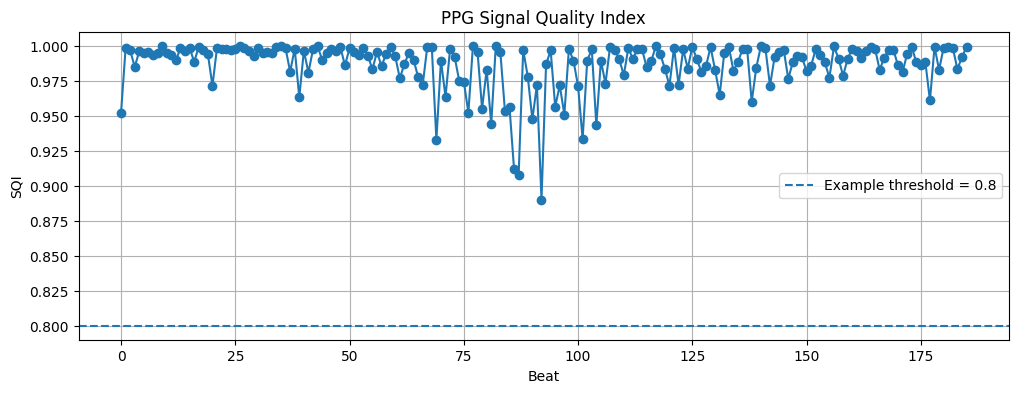

In [42]:
plt.figure(figsize=(12, 4))

plt.plot(ppg_sqi_values, marker='o')

plt.axhline(
    0.8,
    linestyle='--',
    label='Example threshold = 0.8'
)

plt.xlabel("Beat")
plt.ylabel("SQI")
plt.title("PPG Signal Quality Index")

plt.legend()
plt.grid(True)

plt.show()

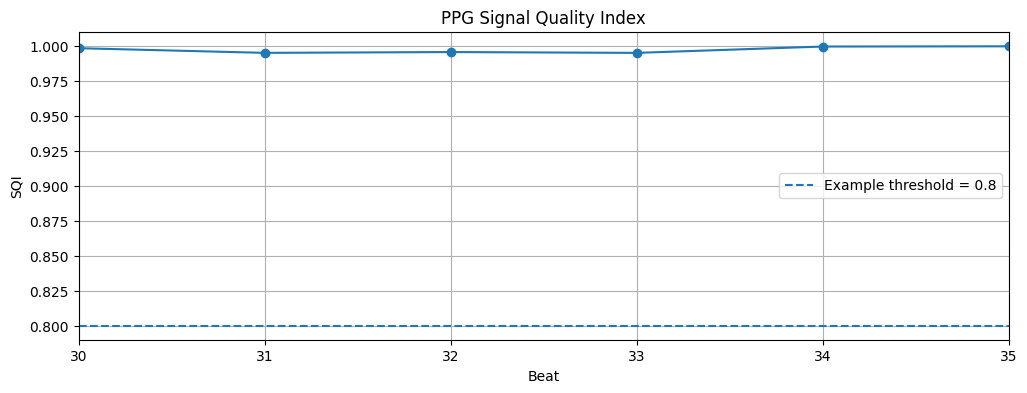

In [44]:
plt.figure(figsize=(12, 4))

plt.plot(ppg_sqi_values, marker='o')

plt.axhline(
    0.8,
    linestyle='--',
    label='Example threshold = 0.8'
)

plt.xlabel("Beat")
plt.ylabel("SQI")
plt.title("PPG Signal Quality Index")

plt.legend()
plt.grid(True)

plt.xlim(30, 35)

plt.show()

In [45]:
SQI_THRESHOLD = 0.8

good_beats = ppg_sqi_values >= SQI_THRESHOLD

print("Total beats:", len(ppg_sqi_values))
print("Good beats:", np.sum(good_beats))
print("Bad beats:", np.sum(~good_beats))

Total beats: 186
Good beats: 186
Bad beats: 0


In [46]:
good_percentage = np.mean(good_beats) * 100

print(f"Good signal percentage: {good_percentage:.2f}%")

Good signal percentage: 100.00%


In [47]:
fiducials.to_csv(
    "ppg_fiducials.csv",
    index=False
)

print("Fiducials saved.")

Fiducials saved.


In [48]:
sqi_df = pd.DataFrame({
    "beat": np.arange(len(ppg_sqi_values)),
    "SQI": ppg_sqi_values,
    "good": good_beats
})

sqi_df.to_csv(
    "ppg_sqi.csv",
    index=False
)

print("SQI saved.")

SQI saved.


In [49]:
biomarker_tables = []

for category, values in bm_vals.items():

    if isinstance(values, pd.DataFrame):
        temp = values.copy()
        temp["category"] = category
        biomarker_tables.append(temp)

if biomarker_tables:
    biomarkers_df = pd.concat(
        biomarker_tables,
        axis=1
    )

    biomarkers_df.to_csv(
        "ppg_biomarkers.csv",
        index=False
    )

    print("Biomarkers saved.")
else:
    print("Biomarker format needs inspection.")

Biomarkers saved.
